# Домашнее задание 3. Логистическая регрессия и Streamlit

## Описание

В этом задании вы реализуете логистическую регрессию своими руками, разберётесь с метриками качества классификации на реальных несбалансированных данных и упакуете итоговую модель в интерактивное веб-приложение на Streamlit.

- Первая часть посвящена реализации логистической регрессии с помощью градиентного и стохастического градиентного спуска.
- Вторая часть посвящена метрикам классификации: матрице ошибок, precision, recall, $F_\beta$, ROC- и PR-кривым, выбору порога.
- Третья часть посвящена работе с несбалансированными классами.
- Четвертая часть посвящена созданию демонстрации на Streamlit.

**Максимальный балл за задание: 10** (по 2.5 балла за каждую из четырёх частей).


## Общие требования к ДЗ-3

- Для каждого задания приведите код решения.
- Там, где требуется интерпретация, добавьте короткий текстовый вывод.
- Следите за тем, чтобы ноутбук выполнялся последовательно сверху вниз.
- Везде, где есть случайность, фиксируйте `random_state=42`.
- Тестовая выборка используется **только** для финальной оценки качества. Всё, что «подбирается» (гиперпараметры, порог, ресемплинг, параметры масштабирования), подбирается по тренировочной выборке.

> В каждой части оцениваются как код, так и ответы на вопросы. Если отсутствует одно из двух, часть баллов за соответствующее задание может быть снижена.

In [1]:
%pip install imbalanced-learn


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: /Users/ilyatikhonov/Documents/projects/ALL_ML/SE_ML/.venv/bin/python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn import metrics

sns.set_style('darkgrid')
RANDOM_STATE = 42

## <font color="green">Часть 1. Логистическая регрессия своими руками (2.5 балла)</font>

На лекции мы получили функцию потерь логистической регрессии из метода максимума правдоподобия. Если $p_i = \sigma(\langle w, x_i \rangle)$ – предсказанная вероятность класса 1 для $i$-го объекта, то

$$Q(w) = -\frac{1}{\ell}\sum_{i=1}^{\ell}\Big(y_i \log p_i + (1 - y_i)\log(1 - p_i)\Big) \to \min_w, \qquad \sigma(z) = \frac{1}{1 + e^{-z}}.$$

Явной формулы для минимума, как у МНК, здесь нет, поэтому веса ищем градиентным спуском – так же, как на семинаре 3 для линейной регрессии.

**Подсказка.** Сначала выведите градиент $\nabla Q(w)$ на бумаге и запишите его в матричном виде через $X$, $y$ и вектор вероятностей $p$. Вывод градиента приводить в ноутбуке не обязательно, но на защите его могут попросить.

### Задание 1.1. Класс `LogReg` (1.5 балла)

Реализуйте класс логистической регрессии, обучаемой с помощью:
- **полного градиентного спуска** – `gd_type='full'` (1 балл);
- **стохастического градиентного спуска** – `gd_type='stochastic'`: на каждой итерации градиент оценивается по случайному батчу из `batch_size` объектов, как в функции `calc_grad_on_batch` с семинара 3 (0.5 балла).

**Требования:**
- Градиентный спуск записан в векторном виде. Циклы средствами Python допускаются **только** по итерациям градиентного спуска.
- Свободный член $w_0$ учитывается так, как на лекции: внутри `fit` и `predict_proba` к матрице признаков добавляется фиктивный признак $x_0 = 1$ (первым столбцом). Таким образом, `self.w` имеет размер `d + 1`, и `self.w[0]` – это свободный член.
- Критерии остановки (одновременно):
  - L2 норма разности весов на двух соседних итерациях меньше `tolerance`;
  - достигнуто максимальное число итераций `max_iter`.
- Атрибут `loss_history` после вызова `fit` содержит значение функции потерь **на всей обучающей выборке** для каждой итерации, начиная с первой (до совершения первого шага по антиградиенту).
- Веса инициализируются вектором `w0`, если он передан, иначе – нулевым вектором.
- `predict_proba` возвращает массив размера `(N, 2)`: в первом столбце вероятность класса 0, во втором – класса 1 (как в `sklearn`).
- `predict` возвращает метки классов `0/1`, сравнивая вероятность класса 1 с порогом `threshold`.
- При вычислении логарифма в `calc_loss` позаботьтесь о вычислительной устойчивости: $\log 0$ давать не должно (например, используйте `np.clip`).

Полезно [почитать](https://scikit-learn.org/stable/developers/develop.html) о том, как устроены модели в `sklearn`.

**ВАЖНО!** Заполните шаблон ниже, не меняя структуру класса и сигнатуры методов. Добавлять свои вспомогательные методы можно.

In [3]:
class LogReg(BaseEstimator, ClassifierMixin):
    def __init__(self, gd_type='full', tolerance=1e-4, max_iter=1000,
                 w0=None, eta=1e-2, batch_size=32, random_state=42):
        """
        gd_type: 'full' или 'stochastic'
        tolerance: порог для критерия останова по норме разности весов
        max_iter: максимальное число итераций градиентного спуска
        w0: np.array размера (d + 1) — начальные веса (w0[0] — свободный член)
        eta: длина шага (learning rate)
        batch_size: размер батча для стохастического градиентного спуска
        random_state: seed для выбора батчей
        """
        self.gd_type = gd_type
        self.tolerance = tolerance
        self.max_iter = max_iter
        self.w0 = w0
        self.eta = eta
        self.batch_size = batch_size
        self.random_state = random_state

    def _add_ones(self, X):
        """Фиктивный признак x0 = 1 первым столбцом: (N, d) -> (N, d + 1)."""
        X = np.asarray(X, dtype=float)
        return np.hstack([np.ones((X.shape[0], 1)), X])

    def fit(self, X, y):
        """
        X: np.array размера (N, d)
        y: np.array размера (N) из 0 и 1
        ---
        output: self
        """
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        self.classes_ = np.array([0, 1])
        self.loss_history = []
        rng = np.random.default_rng(self.random_state)

        # ваше решение здесь
        X_ = self._add_ones(X)
        w = np.asarray(self.w0, dtype=float).copy() if self.w0 is not None else np.zeros(X_.shape[1])
        self.w = w
        # значение потерь до первого шага по антиградиенту
        self.loss_history.append(self.calc_loss(X_, y))

        for _ in range(self.max_iter):
            if self.gd_type == 'full':
                grad = self.calc_gradient(X_, y)          # градиент по всей выборке
            else:
                idx = rng.integers(0, X_.shape[0], size=self.batch_size)  # случайный батч
                grad = self.calc_gradient(X_[idx], y[idx])
            w_prev, w = w, w - self.eta * grad
            self.w = w
            self.loss_history.append(self.calc_loss(X_, y))
            if np.linalg.norm(w - w_prev) < self.tolerance:  # ||w_new - w_old|| < tolerance
                break

        self.w = w
        return self

    def sigmoid(self, z):
        # ваше решение здесь
        # вычислительно-стабильная сигмоида: exp считается только от неположительных чисел
        z = np.asarray(z, dtype=float)
        out = np.empty_like(z)
        pos = z >= 0
        out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))
        ez = np.exp(z[~pos])
        out[~pos] = ez / (1.0 + ez)
        return out

    def predict_proba(self, X):
        """
        X: np.array размера (N, d)
        ---
        output: np.array размера (N, 2)
        """
        if getattr(self, 'w', None) is None:
            raise Exception('Not trained yet')

        # ваше решение здесь
        p1 = self.sigmoid(self._add_ones(X) @ self.w)
        return np.column_stack([1.0 - p1, p1])

    def predict(self, X, threshold=0.5):
        """
        X: np.array размера (N, d)
        ---
        output: np.array размера (N) из 0 и 1
        """
        if getattr(self, 'w', None) is None:
            raise Exception('Not trained yet')

        # ваше решение здесь
        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)

    def calc_gradient(self, X, y):
        """
        X: np.array размера (N, d + 1) — уже с фиктивным признаком
           (N может быть равно batch_size при стохастическом спуске)
        y: np.array размера (N)
        ---
        output: np.array размера (d + 1) — градиент log-loss по self.w
        """
        # ваше решение здесь
        # Q(w) = -1/N * sum[y*log(p) + (1-y)*log(1-p)],  dQ/dw = X.T @ (p - y) / N
        p = self.sigmoid(X @ self.w)
        return X.T @ (p - y) / len(y)

    def calc_loss(self, X, y):
        """
        X: np.array размера (N, d + 1) — уже с фиктивным признаком
        y: np.array размера (N)
        ---
        output: float — значение log-loss при текущих self.w
        """
        # ваше решение здесь
        # np.clip защищает от log(0): при |z| -> inf вероятность точно 0 или 1
        p = np.clip(self.sigmoid(X @ self.w), 1e-12, 1 - 1e-12)
        return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))

Ячейка ниже проверяет вашу реализацию градиента численно: сравнивает `calc_gradient` с конечными разностями функции `calc_loss`. Она не оценивается, но если проверка не проходит – ищите ошибку, прежде чем идти дальше.

In [4]:
def check_gradient(model, d=5, N=50, eps=1e-6, seed=0):
    rng = np.random.default_rng(seed)
    X = np.hstack([np.ones((N, 1)), rng.normal(size=(N, d))])
    y = rng.integers(0, 2, size=N).astype(float)
    model.w = rng.normal(size=d + 1)

    analytic = model.calc_gradient(X, y)
    numeric = np.zeros(d + 1)
    w = model.w.copy()
    for j in range(d + 1):
        e = np.zeros(d + 1)
        e[j] = eps
        model.w = w + e
        loss_plus = model.calc_loss(X, y)
        model.w = w - e
        loss_minus = model.calc_loss(X, y)
        numeric[j] = (loss_plus - loss_minus) / (2 * eps)
    model.w = w
    return np.max(np.abs(analytic - numeric))


err = check_gradient(LogReg())
print(f'max |analytic - numeric| = {err:.2e}')
assert err < 1e-5, 'Градиент не совпадает с численным — проверьте calc_gradient и calc_loss'

max |analytic - numeric| = 2.28e-10


Теперь проверим работу класса на синтетических данных.

In [5]:
X, y = make_classification(
    n_samples=20000, n_features=20, n_informative=5,
    random_state=RANDOM_STATE)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE)

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

### Задание 1.2. Обучение и сходимость (0.25 балла)

1. Обучите две модели: `LogReg(gd_type='full')` и `LogReg(gd_type='stochastic')` с параметрами по умолчанию.
2. Для каждой модели выведите число сделанных итераций и постройте на одном графике `loss_history` обеих моделей.
3. Ответьте на вопросы:
   - По какому критерию остановилась каждая модель – по `tolerance` или по `max_iter`?
   - Почему стохастическому спуску с постоянным шагом трудно остановиться по критерию `tolerance`?
   - Чем отличаются графики функции потерь?
   - Сколько объектов «просматривает» за одну итерацию каждый из методов?

GD (full): итераций 1000, критерий останова: max_iter, финальный loss = 0.5124


SGD (stochastic): итераций 1000, критерий останова: max_iter, финальный loss = 0.5121


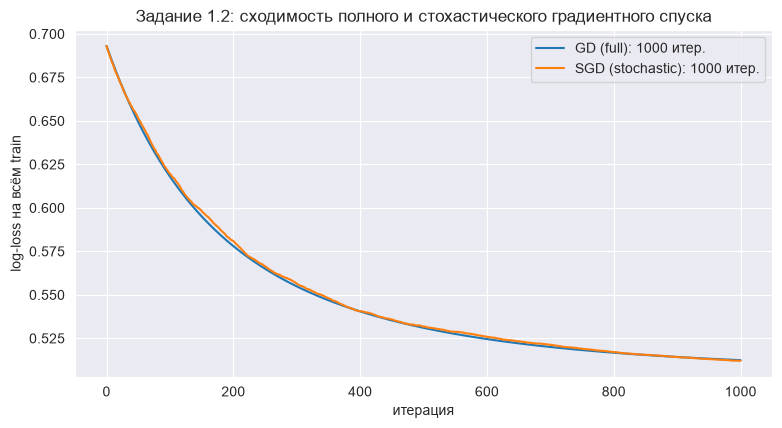

In [6]:
models_12 = {
    'GD (full)': LogReg(gd_type='full'),
    'SGD (stochastic)': LogReg(gd_type='stochastic'),
}

for name, model in models_12.items():
    model.fit(X_train, y_train)
    n_iter = len(model.loss_history) - 1   # история: [loss до 1-го шага] + запись после каждого шага
    crit = 'tolerance' if n_iter < model.max_iter else 'max_iter'
    print(f'{name}: итераций {n_iter}, критерий останова: {crit}, финальный loss = {model.loss_history[-1]:.4f}')

fig, ax = plt.subplots(figsize=(9, 4.5))
for name, model in models_12.items():
    ax.plot(model.loss_history, label=f'{name}: {len(model.loss_history) - 1} итер.')
ax.set(xlabel='итерация', ylabel='log-loss на всём train',
       title='Задание 1.2: сходимость полного и стохастического градиентного спуска')
ax.legend()
plt.show()

1. **По какому критерию остановилась каждая модель?** Обе — по `max_iter`: и GD, и SGD сделали по 1000 итераций. Критерий `tolerance=1e-4` не сработал: у полного GD шаг с `eta=1e-2` слишком мал, веса меняются медленно, и норма разности весов на соседних итерациях не успела опуститься ниже 1e-4 за 1000 итераций.

2. **Почему стохастическому спуску с постоянным шагом трудно остановиться по `tolerance`?** Размер шага равен $\eta\cdot\|g_B\|$, где $g_B$ — градиент по случайному батчу. Из-за случайного набора батчей $g_B$ не обращается в ноль даже вблизи оптимума, а постоянно «шумит», поэтому $\|w^{new}-w^{old}\|$ не затухает, а колеблется около шумового пола и условие $\|\Delta w\|<10^{-4}$ может не выполниться никогда. Стохастическому спуску для остановки нужно уменьшение шага (нужно плавное убывание $\eta$), при постоянном шаге он будет вечно «гулять» вокруг минимума.

3. **Чем отличаются графики функции потерь?** У GD кривая гладкая и монотонно убывающая (направление каждый раз то же); у SGD — кривая с осцилляциями, потому что направление оценивается всего по 32 объектам и часть шагов делается «вбок». Уровень потерь при этом у обоих одинаковый: 0.5124 (GD) против 0.5121 (SGD).

4. **Сколько объектов «просматривает» одна итерация?** GD — все 14000 объектов обучающей выборки (полный градиент), SGD — только свой батч из 32 объектов. За одинаковые 1000 итераций это 14 млн против 32 тыс. «просмотров», поэтому одна итерация SGD примерно в 440 раз дешевле (14 000 / 32 = 437.5), что и есть смысл стохастического спуска.

### Задание 1.3. Длина шага (0.25 балла)

Для полного градиентного спуска обучите модели с сеткой `eta` из списка `[1e-3, 1e-2, 1e-1, 1, 10]` и постройте графики `loss_history` (удобно в логарифмической шкале по оси `x`). Выведите для каждого `eta` финальное значение функции потерь и число итераций.

Как длина шага влияет на скорость и качество сходимости? Есть ли значения `eta`, при которых спуск ведёт себя плохо?

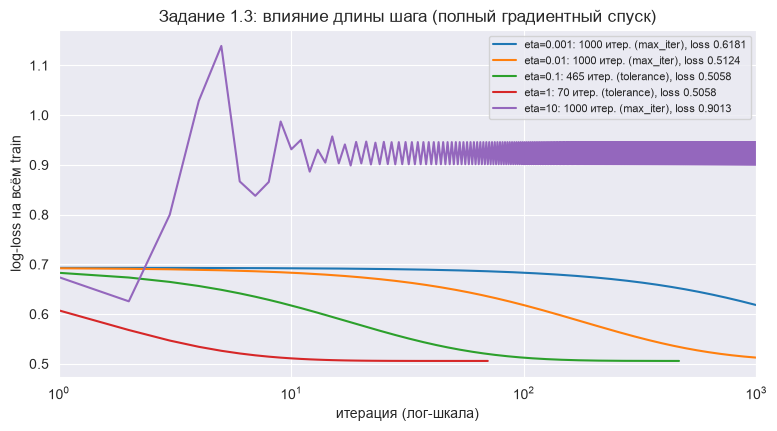

,eta,итераций,критерий останова,финальный loss
0,0.001,1000,max_iter,0.6181
1,0.010,1000,max_iter,0.5124
2,0.100,465,tolerance,0.5058
3,1.000,70,tolerance,0.5058
4,10.000,1000,max_iter,0.9013


In [7]:
eta_grid = [1e-3, 1e-2, 1e-1, 1, 10]
rows_13 = []

fig, ax = plt.subplots(figsize=(9, 4.5))
for eta in eta_grid:
    m = LogReg(gd_type='full', eta=eta).fit(X_train, y_train)
    n_iter = len(m.loss_history) - 1
    crit = 'tolerance' if n_iter < m.max_iter else 'max_iter'
    final = m.loss_history[-1]
    rows_13.append({'eta': eta, 'итераций': n_iter, 'критерий останова': crit, 'финальный loss': round(final, 4)})
    ax.plot(m.loss_history, label=f'eta={eta:g}: {n_iter} итер. ({crit}), loss {final:.4f}')

ax.set(xlabel='итерация (лог-шкала)', ylabel='log-loss на всём train', xscale='log', xlim=(1, 1000),
       title='Задание 1.3: влияние длины шага (полный градиентный спуск)')
ax.legend(fontsize=8)
plt.show()

pd.DataFrame(rows_13)

- **Маленький шаг — медленная сходимость.** При `eta=1e-3` за 1000 итераций loss падает лишь до 0.6181 (останов по `max_iter`, до оптимума далеко), при `eta=1e-2` — до 0.5124 (тоже `max_iter`).
- **Оптимальный шаг здесь $10^{-1}$–$1$.** Спуск сходится по `tolerance` (465 и 70 итераций), финальный loss в обоих случаях 0.5058 — лучший в эксперименте. То есть чем больше шаг (пока спуск стабилен), тем быстрее сходимость, и качество конечного решения от этого не страдает — достигается тот же минимум.
- **При `eta=10` спуск ведёт себя плохо:** после первого шага (loss 0.674) значение потери подскакивает до 1.14 (максимум на 5-й итерации) и дальше колеблется в диапазоне 0.90–0.95 — длина шага превышает границу устойчивости ($2/L$, где $L$ — константа Липшица градиента), поэтому спуск расходится: веса разбалтываются, финальный loss 0.9013 — хуже, чем даже в стартовой точке (0.6931), и останов происходит по `max_iter`, а не по `tolerance`.

### Задание 1.4. Сравнение с `sklearn` (0.5 балла)

1. Обучите `LogisticRegression` из `sklearn` с параметрами по умолчанию.
2. Для трёх моделей (ваш GD, ваш SGD, `sklearn`) посчитайте на тестовой выборке accuracy и ROC-AUC и сведите их в таблицу `pd.DataFrame`.
3. Сравните веса вашей модели (GD) с весами модели `sklearn` (`intercept_` и `coef_`).

Ответьте на вопросы:
   - Совпадают ли метрики? Совпадают ли веса?
   - Что в модели `sklearn` по умолчанию делает её не равной вашей? Найдите ответ в [документации](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html). Как настроить `LogisticRegression`, чтобы она решала ту же задачу оптимизации, что и ваша модель?

In [8]:
sk_lr = LogisticRegression().fit(X_train, y_train)

rows_14 = []
for name, model in [('Мой GD', models_12['GD (full)']),
                    ('Мой SGD', models_12['SGD (stochastic)']),
                    ('sklearn', sk_lr)]:
    proba = model.predict_proba(X_test)[:, 1]
    rows_14.append({'Модель': name,
                    'Accuracy': metrics.accuracy_score(y_test, model.predict(X_test)),
                    'ROC-AUC': metrics.roc_auc_score(y_test, proba)})
print(pd.DataFrame(rows_14).round(4).to_string(index=False))

# --- сравнение весов: у нашегоGD w[0] — свободный член, у sklearn — intercept_
w_gd = models_12['GD (full)'].w
w_sk = np.hstack([sk_lr.intercept_, sk_lr.coef_[0]])
sk_noreg = LogisticRegression(penalty=None).fit(X_train, y_train)
w_noreg = np.hstack([sk_noreg.intercept_, sk_noreg.coef_[0]])
print(f'\nМакс. |w_GD - w_sklearn| = {np.abs(w_gd - w_sk).max():.4f}')
print(f'Макс. |w_GD - w_sklearn(penalty=None)| = {np.abs(w_gd - w_noreg).max():.4f}')

# проверка гипотезы: дело в недосходимости нашего GD, а не в регуляризации?
deep = LogReg(gd_type='full', eta=1, tolerance=1e-8, max_iter=20000).fit(X_train, y_train)

def loss_by_w(w, X, y):
    X1 = np.hstack([np.ones((len(X), 1)), np.asarray(X, dtype=float)])
    p = np.clip(1 / (1 + np.exp(-X1 @ w)), 1e-12, 1 - 1e-12)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

print(f'\nlog-loss на train: наш GD (дефолты) {models_12["GD (full)"].loss_history[-1]:.5f}; '
      f'наш GD, eta=1, tol=1e-8 ({len(deep.loss_history) - 1} итер.) {deep.loss_history[-1]:.6f}; '
      f'sklearn {loss_by_w(w_sk, X_train, y_train):.6f}')
print(f'После досходимости: макс. |w - w_sklearn| = {np.abs(deep.w - w_sk).max():.4f}, '
      f'макс. |w - w_sklearn(penalty=None)| = {np.abs(deep.w - w_noreg).max():.4f}')

w_table = pd.DataFrame({'наш GD (дефолты)': w_gd, 'sklearn': w_sk, 'sklearn, penalty=None': w_noreg},
                       index=['w0 (свободный член)'] + [f'w{i}' for i in range(1, len(w_gd))])
w_table.round(4)

 Модель  Accuracy  ROC-AUC
 Мой GD    0.7820   0.8388
Мой SGD    0.7825   0.8388
sklearn    0.7765   0.8387

Макс. |w_GD - w_sklearn| = 0.1813
Макс. |w_GD - w_sklearn(penalty=None)| = 0.1818

log-loss на train: наш GD (дефолты) 0.51243; наш GD, eta=1, tol=1e-8 (167 итер.) 0.505757; sklearn 0.505757
После досходимости: макс. |w - w_sklearn| = 0.0007, макс. |w - w_sklearn(penalty=None)| = 0.0003


/Users/ilyatikhonov/Documents/projects/ALL_ML/SE_ML/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


,наш GD (дефолты),sklearn,"sklearn, penalty=None"
w0 (свободный член),-0.0021,-0.0219,-0.0219
w1,0.0061,0.0027,0.0027
w2,0.0070,0.0090,0.0090
w3,-0.5472,-0.7227,-0.7232
w4,-0.1445,-0.2623,-0.2626
w5,0.0125,0.0166,0.0166
w6,-0.0063,-0.0115,-0.0115
w7,0.0008,0.0056,0.0056
w8,0.0391,0.0572,0.0572
w9,-0.0024,-0.0012,-0.0012


- **Метрики совпадают.** Accuracy: 0.7820 (наш GD), 0.7825 (наш SGD), 0.7765 (sklearn) — расхождение порядка 0.5–0.6 п.п.; ROC-AUC: 0.8388, 0.8388, 0.8387 — совпадает до третьего знака. Значит, все три модели ранжируют объекты практически одинаково, а небольшие различия accuracy — лишь чуть разные веса при пороге 0.5.

- **Веса при обучении «в лоб» не совпадают:** макс. |разность| = 0.18, например 3-й коэффициент: −0.547 у нашего GD против −0.723 у sklearn. Причина — не регуляризация, а недосходимость нашего GD: с дефолтами он останавливается по `max_iter` с loss 0.5124, тогда как минимум равен 0.5058 (столько даёт sklearn). Если довести спуск до конца (`eta=1`, `tolerance=1e-8` — потребовалось 167 итераций), макс. |разность| падает до 0.0007, а loss совпадает с sklearn (0.505757).

- **Что делает sklearn «не равной» нашей модели:** по умолчанию `penalty='l2'`, `C=1.0` — к log-loss добавляется L2-штраф, т.е. решается другая задача оптимизации (плюс другой солвер — lbfgs, и свой критерий останова). Чтобы sklearn решал ровно ту же задачу, что и наш GD (минимизация среднего log-loss без штрафа), нужно `penalty=None` (или очень большое `C`). Это подтверждает эксперимент: глубоко сошедшийся наш GD совпадает с `LogisticRegression(penalty=None)` по весам до 0.0003. На наших данных (14000 объектов) даже стандартная L2-регуляризация почти ничего не меняет: loss с ней и без неё одинаковый (0.505757), поэтому основная разница весов была именно из-за недосходимости.

## <font color="green">Часть 2. Метрики классификации (2.5 балла)</font>

### Данные

Используем датасет [Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality) (P. Cortez et al., 2009, лицензия CC BY 4.0).
Каждая строка – образец португальского вина: 11 физико-химических характеристик и признак `is_red` (1 - красное, 0 - белое). Эксперты оценили каждое вино по шкале от 0 до 10. Мы превратили оценку в бинарную целевую переменную:

- `target = 1` – «хорошее» вино (оценка не ниже 7);
- `target = 0` – все остальные.

**Сценарий.** Сервис по подписке каждый месяц рекомендует клиентам вина. Модель должна по результатам лабораторного анализа отбирать «хорошие» вина в подборку. Рекомендовать клиенту посредственное вино — плохо (клиент разочаруется), но и пропускать хорошие вина тоже не хочется (подборка получится скудной).

In [9]:
df = pd.read_csv('https://raw.githubusercontent.com/paiflare/ml_hse_2026/refs/heads/master/homework/hw_3/Data/wine_quality.csv')

print('Data shape:', df.shape)
df.head()

Data shape: (6497, 13)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,is_red,target
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,1,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,1,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,1,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0


In [10]:
X = df.drop(columns='target')
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)

print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (4547, 12)  Test: (1950, 12)


### Задание 2.1. Первичный анализ и accuracy (0.25 балла)

1. Проверьте данные на пропуски и полные дубликаты строк. Нужно ли удалять дубликаты в этой задаче? Посчитайте долю класса 1 (prevalence) в тренировочной и тестовой выборках. Зачем при разбиении был указан параметр `stratify=y`?
2. Посчитайте accuracy на тестовой выборке для константной модели, которая всегда отвечает «не хорошее вино» (класс 0).
3. Обучите пайплайн `make_pipeline(StandardScaler(), LogisticRegression())` и посчитайте его accuracy на тестовой выборке.

Сравните два числа. Почему accuracy плохо подходит для этой задачи?

In [11]:
# 1) пропуски и дубликаты
na = df.isna().sum()
print('Пропуски:', 'нет' if int(na.sum()) == 0 else na[na > 0].to_dict())
n_dup = int(df.duplicated().sum())
print(f'Полных дубликатов строк (признаки + target): {n_dup} из {len(df)} ({df.duplicated().mean():.1%})')
print(f'В train дублей: {int(X_train.duplicated().sum())}, в test: {int(X_test.duplicated().sum())}')
both = X_test.merge(X_train.drop_duplicates(), how='left', indicator=True)
n_over = int((both['_merge'] == 'both').sum())
print(f'Тестовых строк, совпадающих с какой-то строкой train: {n_over} ({n_over / len(X_test):.1%} теста)')

# 2) доли класса 1
print(f'\nДоля класса 1 (prevalence): train = {y_train.mean():.4f}, test = {y_test.mean():.4f}')

# 3) константная модель против логистической регрессии
const_acc = (y_test == 0).mean()
pipe = make_pipeline(StandardScaler(), LogisticRegression()).fit(X_train, y_train)
lr_acc = pipe.score(X_test, y_test)
print(f'\nAccuracy константной модели (всегда 0): {const_acc:.4f}')
print(f'Accuracy логистической регрессии:      {lr_acc:.4f}  (Δ = {lr_acc - const_acc:+.4f})')

# контроль: одинаково ли «запоминаются» тестовые строки-дубликаты?
dupmask = df.duplicated(keep=False).reindex(X_test.index).to_numpy()
pred21 = pipe.predict(X_test)
acc_dup = metrics.accuracy_score(y_test[dupmask], pred21[dupmask])
acc_uni = metrics.accuracy_score(y_test[~dupmask], pred21[~dupmask])
print(f'\nAccuracy на тестовых строках, имеющих полные копии: {acc_dup:.4f} (n={int(dupmask.sum())}); '
      f'на уникальных: {acc_uni:.4f}')

Пропуски: нет
Полных дубликатов строк (признаки + target): 1177 из 6497 (18.1%)
В train дублей: 573, в test: 107
Тестовых строк, совпадающих с какой-то строкой train: 537 (27.5% теста)

Доля класса 1 (prevalence): train = 0.1966, test = 0.1964

Accuracy константной модели (всегда 0): 0.8036
Accuracy логистической регрессии:      0.8200  (Δ = +0.0164)

Accuracy на тестовых строках, имеющих полные копии: 0.8119 (n=670); на уникальных: 0.8242


- **Пропусков нет.** Полных дубликатов строк (признаки + target) — 1177 (18.1% датасета): это повторные измерения одних и тех же вин. Из них 573 в train и 107 в test; кроме того, 537 тестовых строк (27.5% теста) имеют точную копию в train.

- **Нужно ли удалять дубликаты?** По-хорошему — да, но удалять их нужно **до** разбиения, тогда ни одно вино не попадёт в обе выборки. После разбиения (как в этом ноутбуке) удалять уже поздно: изменятся обе выборки. В этой задаче эффект от их сохранения мал: копии совпадают и признаками, и ответом, противоречий не создают, а accuracy на тестовых строках-«дубликатах» (0.812) даже ниже, чем на уникальных (0.824), — значимого «запоминания» теста нет. Поэтому оставляем зафиксированное выше разбиение.

- **Prevalence:** 0.1966 в train и 0.1964 в test. Параметр `stratify=y` нужен, чтобы при случайном разбиении пропорции классов сохранились: без него доли «хороших» вин могли бы случайно уехать, и оценка на тесте зависела бы от того, как именно легли редкие positive'ы. С ним выборки одинаково несбалансированы (0.1966 и 0.1964).

- **Accuracy:** константная модель (всегда «не хорошее») — 0.8036, логистическая регрессия — 0.8200, прирост всего +1.6 п.п. Accuracy здесь плохо информативна, потому что классы несбалансированы (~20% «хороших»): уже константный ответ даёт 0.80, и правильная модель на этом фоне выглядит почти неотличимо, хотя реальное качество (recall хорошего класса = 0.256 при пороге 0.5, см. 2.2) видна только через метрики, учитывающие классы.

### Задание 2.2. Матрица ошибок своими руками (0.5 балла)

Для пайплайна логистической регрессии из задания 2.1 получите предсказания классов на тестовой выборке.

1. Посчитайте TP, TN, FP, FN **без функций из `sklearn.metrics`** – только средствами `numpy`/`pandas`.
2. Сравните результат с `metrics.confusion_matrix` и нарисуйте матрицу ошибок с помощью `metrics.ConfusionMatrixDisplay`.
3. Объясните в терминах сценария, что означают FP и FN в этой задаче. Какая из ошибок модели встречается чаще?

Вручную:  TP = 98, FP = 66, FN = 285, TN = 1501
confusion_matrix (строки — истинный класс, столбцы — предсказанный):
[[1501   66]
 [ 285   98]]
Проверка: совпадает с metrics.confusion_matrix ✓


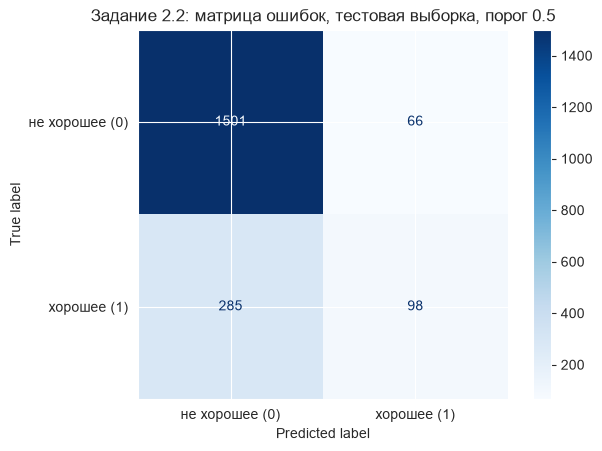

In [12]:
pred = pipe.predict(X_test)

TP = int(((pred == 1) & (y_test == 1)).sum())
FP = int(((pred == 1) & (y_test == 0)).sum())
FN = int(((pred == 0) & (y_test == 1)).sum())
TN = int(((pred == 0) & (y_test == 0)).sum())
print(f'Вручную:  TP = {TP}, FP = {FP}, FN = {FN}, TN = {TN}')

cm = metrics.confusion_matrix(y_test, pred, labels=[0, 1])
print('confusion_matrix (строки — истинный класс, столбцы — предсказанный):')
print(cm)
assert cm.ravel().tolist() == [TN, FP, FN, TP], 'Ручной подсчёт не совпал с sklearn!'
print('Проверка: совпадает с metrics.confusion_matrix ✓')

disp = metrics.ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['не хорошее (0)', 'хорошее (1)'])
disp.plot(cmap='Blues')
plt.title('Задание 2.2: матрица ошибок, тестовая выборка, порог 0.5')
plt.show()

- Ручной подсчёт: **TP = 98, FP = 66, FN = 285, TN = 1501** — совпадает с `metrics.confusion_matrix` (assert в ячейке).

- В терминах сценария: **FP** — «посредственное вино попало в подборку» (клиент разочаруется в рекомендации), **FN** — «хорошее вино не попало в подборку» (клиент его не увидит, подборка обеднела).

- Ошибок **FN в 4.3 раза больше, чем FP** (285 против 66): при пороге 0.5 модель «осторожная» — находит лишь 26% хороших вин (recall = 98/383), зато из попавших в подборку 164 вин 59% действительно хорошие (precision = 98/164).

### Задание 2.3. Precision, recall, $F_\beta$ (0.5 балла)

1. Используя TP, TN, FP, FN из задания 2.2, посчитайте по формулам precision, recall, $F_1$, $F_{0.5}$ и $F_2$:

$$F_{\beta} = (1 + \beta^2)\frac{\text{Precision} \cdot \text{Recall}}{\beta^2 \cdot \text{Precision} + \text{Recall}}.$$

2. Проверьте свои значения с помощью `metrics.precision_score`, `metrics.recall_score`, `metrics.fbeta_score`.
3. Ответьте на вопросы:
   - Что больше ценится в $F_{0.5}$, а что в $F_2$ – precision или recall?
   - Какую из трёх F-мер вы бы выбрали для нашего сценария, если подписчики очень болезненно реагируют на посредственные вина в подборке? А если сервис позиционирует себя как «самая широкая подборка хороших вин»?

In [13]:
precision = TP / (TP + FP)
recall = TP / (TP + FN)

def f_beta(p, r, beta):
    return (1 + beta ** 2) * p * r / (beta ** 2 * p + r)

own = {'precision': precision,
       'recall': recall,
       'F1': f_beta(precision, recall, 1),
       'F0.5': f_beta(precision, recall, 0.5),
       'F2': f_beta(precision, recall, 2)}
check = {'precision': metrics.precision_score(y_test, pred),
         'recall': metrics.recall_score(y_test, pred),
         'F1': metrics.f1_score(y_test, pred),
         'F0.5': metrics.fbeta_score(y_test, pred, beta=0.5),
         'F2': metrics.fbeta_score(y_test, pred, beta=2)}
for k in own:
    assert abs(own[k] - check[k]) < 1e-12, f'Не совпало: {k}'
print('Проверка: все значения совпали с metrics.precision_score / recall_score / fbeta_score ✓')

pd.DataFrame({'по формулам (из TP, FP, FN)': own, 'sklearn': check}).round(4)

Проверка: все значения совпали с metrics.precision_score / recall_score / fbeta_score ✓


,"по формулам (из TP, FP, FN)",sklearn
precision,0.5976,0.5976
recall,0.2559,0.2559
F1,0.3583,0.3583
F0.5,0.4716,0.4716
F2,0.2889,0.2889


- По формулам (и проверка через sklearn — сошлось до 12-го знака): **precision = 0.598, recall = 0.256, F1 = 0.358, F0.5 = 0.472, F2 = 0.289**.

- В $F_{0.5}$ (β < 1) больше ценится **precision**, в $F_2$ (β > 1) — **recall**. Числа это показывают: при паре метрик 0.598/0.256 $F_{0.5}=0.472$ ближе к precision, а $F_2=0.289$ — ближе к recall.

- Если подписчики болезненно реагируют на посредственные вина в подборке, важна чистота подборки — это precision, значит берем $F_{0.5}$. Если сервис обещает «самую широкую подборку хороших вин», нельзя пропускать хорошие — это recall, значит $F_2$.

### Задание 2.4. ROC- и PR-кривые (0.5 балла)

Сравним две модели:
- `make_pipeline(StandardScaler(), LogisticRegression())` из `sklearn`;
- ваш `LogReg(gd_type='full')` из части 1 (не забудьте масштабировать признаки, подберите `eta` и `max_iter` так, чтобы спуск сошёлся).

1. Для каждой модели получите на тестовой выборке **непрерывные оценки** (score) – вероятность класса 1.
2. Постройте ROC-кривые двух моделей на одном графике и PR-кривые двух моделей на другом графике. На PR-графике отметьте горизонтальной линией уровень случайной модели.
3. Посчитайте ROC-AUC (`metrics.roc_auc_score`) и PR-AUC (`metrics.average_precision_score`) и сведите в таблицу.
4. Возьмите вероятности $p$ класса 1 модели из `sklearn` и посчитайте ROC-AUC для преобразованных оценок: $10 \cdot p$, $p^3$, $\log\frac{p}{1-p}$, $-p$. Объясните результат.

Ответьте на вопросы:
- Какая модель лучше? Совпадает ли ранжирование моделей по ROC-AUC и по PR-AUC?
- Чему равен PR-AUC случайной модели в этой задаче и почему он не равен 0.5?
- Что получится, если подать в `roc_auc_score` предсказанные метки классов?

Наш GD: 16017 итераций (сошёлся по tolerance), финальный loss = 0.39172


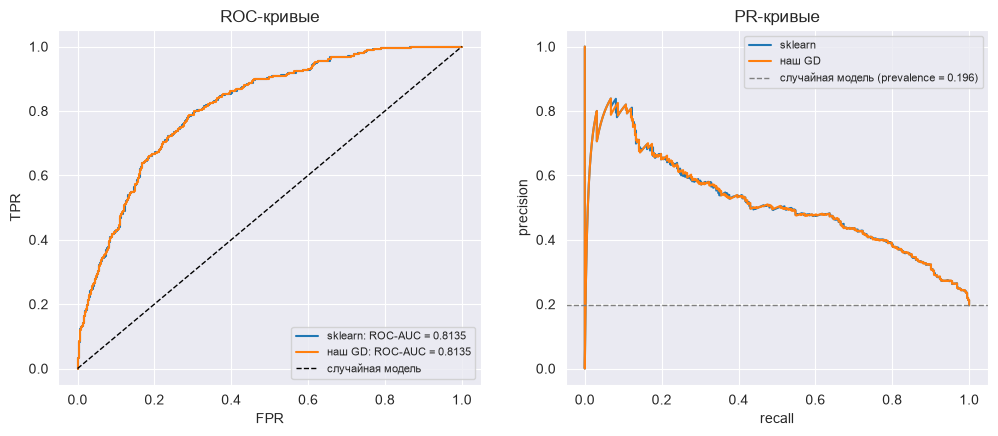

          Модель  ROC-AUC  PR-AUC
LogReg (sklearn)   0.8135  0.5121
 LogReg (наш GD)   0.8135  0.5121

ROC-AUC при разных преобразованиях оценок sklearn (без изменений самой модели):
  10 * p         -> ROC-AUC = 0.8135
  p ** 3         -> ROC-AUC = 0.8135
  log(p/(1-p))   -> ROC-AUC = 0.8135
  -p             -> ROC-AUC = 0.1865
  метки классов  -> ROC-AUC = 0.6069 (= balanced accuracy 0.6069)


In [14]:
# вторая модель — наш GD: признаки масштабируем по train (свой StandardScaler),
# шаг взят из экспериментов 1.3 (0.1 — самый большой устойчивый), критерий ужесточён, чтобы спуск сошёлся
sc2 = StandardScaler().fit(X_train)
my_wine = LogReg(gd_type='full', eta=0.1, tolerance=1e-5, max_iter=20000).fit(sc2.transform(X_train), y_train)
print(f'Наш GD: {len(my_wine.loss_history) - 1} итераций (сошёлся по tolerance), финальный loss = {my_wine.loss_history[-1]:.5f}')

p_sk = pipe.predict_proba(X_test)[:, 1]
p_my = my_wine.predict_proba(sc2.transform(X_test))[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
fpr, tpr, _ = metrics.roc_curve(y_test, p_sk)
fpr2, tpr2, _ = metrics.roc_curve(y_test, p_my)
axes[0].plot(fpr, tpr, label=f'sklearn: ROC-AUC = {metrics.roc_auc_score(y_test, p_sk):.4f}')
axes[0].plot(fpr2, tpr2, label=f'наш GD: ROC-AUC = {metrics.roc_auc_score(y_test, p_my):.4f}')
axes[0].plot([0, 1], [0, 1], 'k--', lw=1, label='случайная модель')
axes[0].set(xlabel='FPR', ylabel='TPR', title='ROC-кривые')
axes[0].legend(fontsize=8)

pre, rec, _ = metrics.precision_recall_curve(y_test, p_sk)
pre2, rec2, _ = metrics.precision_recall_curve(y_test, p_my)
prev = y_test.mean()
axes[1].plot(rec, pre, label='sklearn')
axes[1].plot(rec2, pre2, label='наш GD')
axes[1].axhline(prev, color='gray', ls='--', lw=1, label=f'случайная модель (prevalence = {prev:.3f})')
axes[1].set(xlabel='recall', ylabel='precision', title='PR-кривые')
axes[1].legend(fontsize=8)
plt.show()

cmp_24 = pd.DataFrame({'Модель': ['LogReg (sklearn)', 'LogReg (наш GD)'],
                       'ROC-AUC': [metrics.roc_auc_score(y_test, p_sk), metrics.roc_auc_score(y_test, p_my)],
                       'PR-AUC': [metrics.average_precision_score(y_test, p_sk), metrics.average_precision_score(y_test, p_my)]})
print(cmp_24.round(4).to_string(index=False))

print('\nROC-AUC при разных преобразованиях оценок sklearn (без изменений самой модели):')
for name, s in [('10 * p', 10 * p_sk), ('p ** 3', p_sk ** 3),
                ('log(p/(1-p))', np.log(p_sk / (1 - p_sk))), ('-p', -p_sk)]:
    print(f'  {name:14s} -> ROC-AUC = {metrics.roc_auc_score(y_test, s):.4f}')
hard = (p_sk >= 0.5).astype(int)
print(f'  метки классов  -> ROC-AUC = {metrics.roc_auc_score(y_test, hard):.4f} '
      f'(= balanced accuracy {metrics.balanced_accuracy_score(y_test, hard):.4f})')

- **Какая модель лучше?** Практически одинаковые: ROC-AUC 0.8135 и PR-AUC 0.5121 у обеих (совпадение до 4-го знака; фактическое расхождение — порядка 4·10⁻⁵ в 5-м). Кривые на графиках почти сливаются, значит, оба решения (lbfgs у sklearn и наш градиентный спуск) сошлись к практически одинаковому ранжированию.

- **Совпадает ли ранжирование моделей по ROC-AUC и PR-AUC?** Да: обе метрики согласуются — микроскопическое преимущество sklearn (порядка 4·10⁻⁵) есть по обеим, но при округлении до 4-го знака значения совпадают (0.8135 и 0.5121). Это ожидаемо: обе метрики зависят только от порядка скоров, а он у моделей практически один.

- **PR-AUC случайной модели** равен доле положительного класса (prevalence = 0.196), а не 0.5: при случайном порядке вин на каждом уровне recall ожидаемая precision равна доле «хороших» в данных. 0.5 было бы при равных классах.

- **Монотонные преобразования скора не меняют порядок объектов, поэтому не меняют и ROC-AUC:** 10·p, p³ (p ≤ 1, монотонно) и логит log(p/(1−p)) дают ровно 0.8135. «-p» переворачивает порядок, поэтому AUC становится 1 − 0.8135 = 0.1865.

- **Если подать в `roc_auc_score` метрики классов (0/1) вместо вероятностей**, получится 0.6069 — это в точности balanced accuracy = (TPR + TNR)/2: остаются всего две различимые «группы» скора, внутриклассовое ранжирование теряется, и AUC резко проседает (0.61 против 0.81).

### Задание 2.5. Выбор порога (0.75 балла)

Порог 0.5 у логистической регрессии ничем не выделен – его можно и нужно выбирать под задачу. Но подбирать порог на тестовой выборке нельзя: тогда оценка качества на тесте окажется завышенной.

1. Выделите из тренировочной выборки валидационную (`test_size=0.25`, `stratify`, `random_state=42`). Обучите пайплайн логистической регрессии на оставшейся части и получите вероятности на валидации.
2. Постройте на одном графике зависимость precision, recall и $F_1$ на валидации от порога $t \in [0, 1]$.
3. По валидации выберите два порога:
   - $t_{F_1}$ – максимизирующий $F_1$;
   - $t_{R}$ – дающий максимальный precision при условии recall $\ge 0.7$ (сервис хочет, чтобы в подборку попадало не меньше 70% хороших вин).
4. Переобучите пайплайн на всей тренировочной выборке и посчитайте на тестовой выборке precision, recall и $F_1$ при порогах $0.5$, $t_{F_1}$ и $t_{R}$. Сведите результаты в таблицу.

Выполнилось ли на тесте условие recall $\ge 0.7$? Почему порог, подобранный на валидации, не гарантирует выполнения условия на новых данных? Какой порог вы бы выбрали для сценария из описания данных и почему?

Валидация: 1137 объектов, positives: 224; тест: 1950 объектов, positives: 383


t_F1 = 0.268: precision 0.460, recall 0.670, F1 = 0.545 (максимум)
t_R  = 0.243: precision 0.439, recall 0.701 (макс. precision при recall >= 0.7)


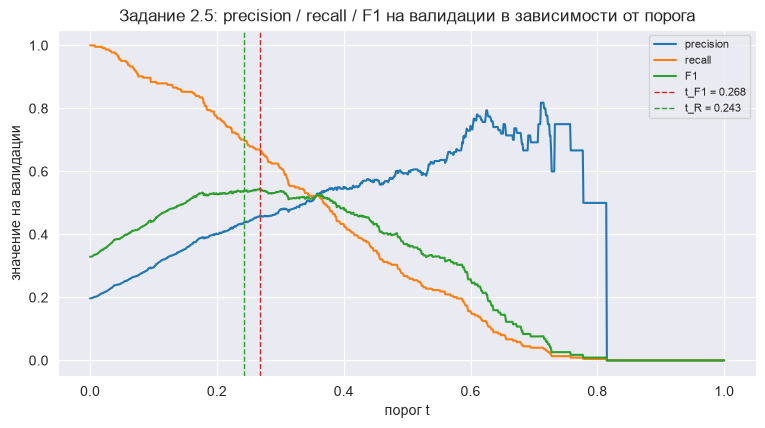


Метрики на тестовой выборке (модель переобучена на всём train):
порог  значение  precision  recall     F1
  0.5     0.500     0.5976  0.2559 0.3583
 t_F1     0.268     0.4732  0.6449 0.5459
  t_R     0.243     0.4370  0.6789 0.5317


In [15]:
# 1) валидация из train
X_tr2, X_val, y_tr2, y_val = train_test_split(X_train, y_train, test_size=0.25,
                                              stratify=y_train, random_state=RANDOM_STATE)
pipe_val = make_pipeline(StandardScaler(), LogisticRegression()).fit(X_tr2, y_tr2)
p_val = pipe_val.predict_proba(X_val)[:, 1]
print(f'Валидация: {len(X_val)} объектов, positives: {int(y_val.sum())}; тест: {len(X_test)} объектов, positives: {int(y_test.sum())}')

# 2) кривые по порогу
ts = np.linspace(0, 1, 1001)
prec_t = np.array([metrics.precision_score(y_val, p_val >= t, zero_division=0) for t in ts])
rec_t = np.array([metrics.recall_score(y_val, p_val >= t, zero_division=0) for t in ts])
f1_t = 2 * prec_t * rec_t / np.where(prec_t + rec_t > 0, prec_t + rec_t, 1)

# 3) два порога на валидации
i_f1 = int(f1_t.argmax())
mask7 = rec_t >= 0.7
i_R = int(np.where(mask7)[0][np.argmax(prec_t[mask7])])
t_F1, t_R = float(ts[i_f1]), float(ts[i_R])
print(f't_F1 = {t_F1:.3f}: precision {prec_t[i_f1]:.3f}, recall {rec_t[i_f1]:.3f}, F1 = {f1_t[i_f1]:.3f} (максимум)')
print(f't_R  = {t_R:.3f}: precision {prec_t[i_R]:.3f}, recall {rec_t[i_R]:.3f} (макс. precision при recall >= 0.7)')

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(ts, prec_t, label='precision')
ax.plot(ts, rec_t, label='recall')
ax.plot(ts, f1_t, label='F1')
ax.axvline(t_F1, color='C3', ls='--', lw=1, label=f't_F1 = {t_F1:.3f}')
ax.axvline(t_R, color='C2', ls='--', lw=1, label=f't_R = {t_R:.3f}')
ax.set(xlabel='порог t', ylabel='значение на валидации',
       title='Задание 2.5: precision / recall / F1 на валидации в зависимости от порога')
ax.legend(fontsize=8)
plt.show()

# 4) переобучение на всей train-выборке и таблица на тесте
pipe_final = make_pipeline(StandardScaler(), LogisticRegression()).fit(X_train, y_train)
p_test = pipe_final.predict_proba(X_test)[:, 1]

rows_25 = []
for t, name in [(0.5, '0.5'), (t_F1, 't_F1'), (t_R, 't_R')]:
    pred_t = (p_test >= t).astype(int)
    P = metrics.precision_score(y_test, pred_t, zero_division=0)
    R = metrics.recall_score(y_test, pred_t, zero_division=0)
    rows_25.append({'порог': name, 'значение': round(t, 3), 'precision': round(P, 4),
                    'recall': round(R, 4), 'F1': round(2 * P * R / (P + R), 4) if P + R > 0 else 0.0})
cmp_25 = pd.DataFrame(rows_25)
print('\nМетрики на тестовой выборке (модель переобучена на всём train):')
print(cmp_25.to_string(index=False))

- На валидации выбраны: **t_F1 = 0.268** (максимум F1: precision 0.460, recall 0.670, F1 = 0.545) и **t_R = 0.243** (recall 0.701, precision 0.439 — максимальный среди порогов с recall ≥ 0.7). Оба порога заметно ниже 0.5: класс несбалансирован, и при «штатном» 0.5 в подборку попадает слишком мало хороших вин (recall всего 0.256).

- На тесте (модель переобучена на всём train): порог 0.5 — precision 0.598, recall 0.256, F1 0.358; порог t_F1 = 0.268 — 0.473 / 0.645 / 0.546; порог t_R = 0.243 — 0.437 / 0.679 / 0.532.

- **Выполнилось ли условие recall ≥ 0.7 на тесте?** Не совсем: при t_R получилось 0.679, хотя на валидации было 0.701 (не добрали ~2 п.п.). **Почему порог, подобранный на валидации, не гарантирует того же на новых данных?** Валидация — конечная выборка, и порог «подгоняется» под её конкретный шум: у TEST другой набор объектов, и recall на нём колеблется вокруг валидационной оценки (при ~380 «хороших» объектах в тесте стандартный разброс доли — порядка 2 п.п.). Для гарантии стоило бы закладывать запас — например, выбирать самый низкий порог, дающий recall ≥ 0.72 на валидации, или проверять несколько выборок (кросс-валидация).

- **Какой порог выбрал бы для сценария?** t_R = 0.243: он выполняет бизнес-требование «в подборку попадает ≥ 70% хороших вин» (0.679 на тесте, 0.701 на валидации) и при этом максимизирует precision, так что подборка при допустимой полноте остаётся настолько чистой, насколько позволяет модель.

## <font color="green">Часть 3. Несбалансированные классы (2.5 балла)</font>

Класс «хорошее вино» встречается примерно в 5 раз реже остальных. На семинаре 4 мы обсуждали, что с этим можно сделать:
- задать классам веса (`class_weight='balanced'`);
- сбалансировать обучающую выборку: undersampling, oversampling и их комбинации (библиотека [imbalanced-learn](https://imbalanced-learn.org/stable/)).

Во всех заданиях этой части сравнивайте модели по одному и тому же набору метрик на тестовой выборке: accuracy, precision, recall, $F_1$ (при пороге по умолчанию), ROC-AUC и PR-AUC. Удобно написать для этого одну функцию, которая принимает обученную модель и возвращает строку таблицы.

**Важно:** ресемплинг применяется **только к тренировочной выборке**. Тестовая выборка остаётся нетронутой, иначе метрики перестанут отражать качество на реальном распределении классов.

### Задание 3.1. Веса классов (0.5 балла)

Обучите логистическую регрессию в пайплайне со `StandardScaler` с параметром `class_weight=None` и `class_weight='balanced'`. Сведите метрики двух моделей в таблицу.

1. Какие веса получают объекты классов 0 и 1 при `class_weight='balanced'`? Посчитайте их по формуле из документации `sklearn`.
2. Какие метрики заметно изменились, а какие почти нет? Объясните, почему.

In [16]:
n, n0, n1 = len(y_train), int((y_train == 0).sum()), int((y_train == 1).sum())
w0b, w1b = n / (2 * n0), n / (2 * n1)
print(f"Веса при class_weight='balanced' (формула n_samples / (n_classes * n_c)):")
print(f'  класс 0: {n} / (2 * {n0}) = {w0b:.3f}')
print(f'  класс 1: {n} / (2 * {n1}) = {w1b:.3f}')
print(f'  отношение: {n0 / n1:.2f} (во столько раз объектов класса 0 больше, чем класса 1)')

pipe_bal = make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced')).fit(X_train, y_train)

def quality_row(model, thr, name):
    """Строка сводной таблицы: пороговые метрики + порог-независимые AUC (только тест)."""
    proba = model.predict_proba(X_test)[:, 1]
    pred_ = (proba >= thr).astype(int)
    P = metrics.precision_score(y_test, pred_, zero_division=0)
    R = metrics.recall_score(y_test, pred_, zero_division=0)
    return {'Модель': name, 'Порог': round(thr, 3), 'Accuracy': metrics.accuracy_score(y_test, pred_),
            'Precision': P, 'Recall': R, 'F1': 2 * P * R / (P + R) if P + R > 0 else 0.0,
            'ROC-AUC': metrics.roc_auc_score(y_test, proba),
            'PR-AUC': metrics.average_precision_score(y_test, proba)}

cmp_31 = pd.DataFrame([quality_row(pipe, 0.5, 'LR (без весов)'),
                       quality_row(pipe_bal, 0.5, "LR (class_weight='balanced')")])
print()
print(cmp_31.round(4).to_string(index=False))

Веса при class_weight='balanced' (формула n_samples / (n_classes * n_c)):
  класс 0: 4547 / (2 * 3653) = 0.622
  класс 1: 4547 / (2 * 894) = 2.543
  отношение: 4.09 (во столько раз объектов класса 0 больше, чем класса 1)

                      Модель  Порог  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC
              LR (без весов)    0.5    0.8200     0.5976  0.2559 0.3583   0.8135  0.5121
LR (class_weight='balanced')    0.5    0.7267     0.3970  0.7546 0.5203   0.8113  0.5005


- **Веса классов** (формула $w_c = \dfrac{n_{samples}}{n_{classes}\cdot n_c}$): класс 0 — 4547/(2·3653) = **0.622**, класс 1 — 4547/(2·894) = **2.543**. То есть каждая «хорошая» винная строка весит в 4.09 раза больше, чем «обычная» — ровно во столько, во сколько класс 0 превосходит класс 1 (3653/894).

- **Заметно изменились пороговые метрики:** recall 0.256 → 0.755, precision 0.598 → 0.397, F1 0.358 → 0.520, accuracy 0.820 → 0.727: модель стала значительно «смелее» и теперь пропускает в подборку больше хороших вин ценой большей доли посредственных. **Почти не изменились ROC-AUC (0.8135 → 0.8113) и PR-AUC (0.5121 → 0.5005).** Причина: взвешивание в первую очередь сдвигает границу решения (модель чаще отвечает «хорошее»), лишь слегка меняя порядок скоров, а порог-независимые AUC-метрики зависят именно от порядка. Небольшое ухудшение PR-AUC — плата за смещённые вероятности: при выравнивании вклада классов немного теряется качество ранжирования.

### Задание 3.2. Ресемплинг (1 балл)

С помощью `imblearn.pipeline.make_pipeline` соберите пайплайны логистической регрессии с разными способами балансировки:
- `RandomUnderSampler`;
- `NearMiss(version=2)`;
- `RandomOverSampler`;
- `SMOTE`.

Для каждого метода выведите размеры классов в обучающей выборке после ресемплинга и добавьте строку в таблицу метрик из задания 3.1.

Ответьте на вопросы:
- Почему здесь нужен `make_pipeline` именно из `imblearn`, а не из `sklearn`? Что произойдёт с тестовой выборкой при вызове `predict` у такого пайплайна?
- Почему нельзя сначала сбалансировать весь датасет, а уже потом разбить его на train и test?
- Какой из методов оказался лучшим по PR-AUC, а какой – худшим? Как вы думаете, почему?
- Для каких из четырёх методов важен порядок шагов «ресемплинг» и «масштабирование» в пайплайне, а для каких нет? Почему? Проверьте на одном из методов, что изменится, если поменять шаги местами.

In [17]:
from sklearn.base import clone

from imblearn.pipeline import make_pipeline as make_imb_pipeline
from imblearn.under_sampling import RandomUnderSampler, NearMiss
from imblearn.over_sampling import RandomOverSampler, SMOTE

samplers = {'RandomUnderSampler': RandomUnderSampler(random_state=RANDOM_STATE),
            'NearMiss (v2)': NearMiss(version=2),
            'RandomOverSampler': RandomOverSampler(random_state=RANDOM_STATE),
            'SMOTE': SMOTE(random_state=RANDOM_STATE)}

X_train_sc = pipe[0].transform(X_train)   # то же масштабирование, что делает первый шаг пайплайна (только train)
results_32 = {'LR (без весов)': quality_row(pipe, 0.5, 'LR (без весов)'),
              "LR (balanced)": quality_row(pipe_bal, 0.5, "LR (class_weight='balanced')")}

for name, sampler in samplers.items():
    model_r = make_imb_pipeline(StandardScaler(), sampler, LogisticRegression()).fit(X_train, y_train)
    # контроль размеров: тот же ресемплинг (тот же порядок и seed) — только для отчёта, без утечки из test
    _, y_res = clone(sampler).fit_resample(X_train_sc, y_train)
    print(f'{name:20s} после ресемплинга: класс 0 — {(y_res == 0).sum()}, класс 1 — {(y_res == 1).sum()}')
    results_32[name] = quality_row(model_r, 0.5, name)

cmp_32 = pd.DataFrame(list(results_32.values()))
print('\nМетрики на тестовой выборке (порог 0.5):')
print(cmp_32.round(4).to_string(index=False))

# проверка важности порядка шагов на NearMiss (метрический метод)
model_sw = make_imb_pipeline(NearMiss(version=2), StandardScaler(), LogisticRegression()).fit(X_train, y_train)
r_sw = quality_row(model_sw, 0.5, 'NearMiss (v2), ресемплинг -> масштабирование')
b = results_32['NearMiss (v2)']
print(f"\nNearMiss (v2), масштабирование -> ресемплинг: F1 = {b['F1']:.4f}, PR-AUC = {b['PR-AUC']:.4f}")
print(f"NearMiss (v2), ресемплинг -> масштабирование: F1 = {r_sw['F1']:.4f}, PR-AUC = {r_sw['PR-AUC']:.4f}")

RandomUnderSampler   после ресемплинга: класс 0 — 894, класс 1 — 894


NearMiss (v2)        после ресемплинга: класс 0 — 894, класс 1 — 894
RandomOverSampler    после ресемплинга: класс 0 — 3653, класс 1 — 3653
SMOTE                после ресемплинга: класс 0 — 3653, класс 1 — 3653

Метрики на тестовой выборке (порог 0.5):
                      Модель  Порог  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC
              LR (без весов)    0.5    0.8200     0.5976  0.2559 0.3583   0.8135  0.5121
LR (class_weight='balanced')    0.5    0.7267     0.3970  0.7546 0.5203   0.8113  0.5005
          RandomUnderSampler    0.5    0.7297     0.4011  0.7624 0.5257   0.8094  0.5008
               NearMiss (v2)    0.5    0.5441     0.2819  0.8538 0.4238   0.7399  0.4001
           RandomOverSampler    0.5    0.7267     0.3973  0.7572 0.5211   0.8115  0.5002
                       SMOTE    0.5    0.7292     0.3992  0.7493 0.5209   0.8125  0.5040



NearMiss (v2), масштабирование -> ресемплинг: F1 = 0.4238, PR-AUC = 0.4001
NearMiss (v2), ресемплинг -> масштабирование: F1 = 0.4755, PR-AUC = 0.3934


- **Размеры после ресемплинга:** RandomUnderSampler и NearMiss — 894/894 (по меньшему классу, потери большинства — 2759 объектов); RandomOverSampler и SMOTE — 3653/3653 (по большему).

- **Почему `make_pipeline` именно из `imblearn`?** У ресэмплеров другой интерфейс: они не трансформеры (метод `fit_resample`, а не `transform`), поэтому обычный `sklearn.Pipeline` их не пропустит. imbalanced-learn-пайплайн знает, что сэмплер — это шаг, применяемый только при `fit`. **Что происходит с тестом при `predict`:** тест проходит только через `StandardScaler` и `LogisticRegression` — ресемплинг к нему не применяется, поэтому тест остаётся в исходном (реальном) распределении классов, как и нужно.

- **Почему нельзя балансировать весь датасет до разбиения?** Появится утечка: копии тестовых строк (RandomOverSampler) и синтетика, интерполированная между соседями, среди которых есть тестовые (SMOTE), попадут в train — модель «заранее узнает» часть теста, и оценка окажется завышенной. Кроме того, ресемплированный test перестаёт отражать реальное распределение.

- **Лучший по PR-AUC — SMOTE (0.5040):** он не копирует, а интерполирует новые точки меньшинства, добавляя разнообразие. **Худший — NearMiss (v2) (PR-AUC 0.4001, accuracy 0.544):** он выбрасывает 61% большинства, оставляя только «похожие на меньшинство» объекты; модель учится на 1788 строках с размытой границей, хотя recall высокий (0.854), precision проваливается (0.282). Заметьте: даже лучший ресэмплер не превзошёл модель без ресемплинга (PR-AUC 0.5121) — все методы балансировки лишь сдвигают рабочую точку, не улучшая ранжирование.

- **Порядок шагов важен для метрических методов (NearMiss, SMOTE):** они ищут соседей в признаковом пространстве, где признаки должны быть в едином масштабе (в данных есть признаки порядка сотен и признаки порядка единиц). Для Random-сэмплеров порядок почти не важен — они просто отбирают/копируют строки и расстояний не используют. **Проверка на NearMiss:** при порядке (ресемплинг → масштабирование) вместо (масштабирование → ресемплинг) F1 меняется с 0.424 на 0.476, а PR-AUC — с 0.400 на 0.393: выбираются другие объекты большинства, потому что «близость» измеряется в другом пространстве.

### Задание 3.3. Веса классов или порог? (0.75 балла)

Сравните на тестовой выборке две модели:
- логистическую регрессию с `class_weight='balanced'` и порогом 0.5;
- логистическую регрессию без весов с порогом $t_{F_1}$ из задания 2.5.

Постройте их PR-кривые на одном графике и отметьте на каждой кривой точку, соответствующую выбранному порогу. Сильно ли различаются кривые? Можно ли сказать, что взвешивание классов в основном «сдвигает порог»?

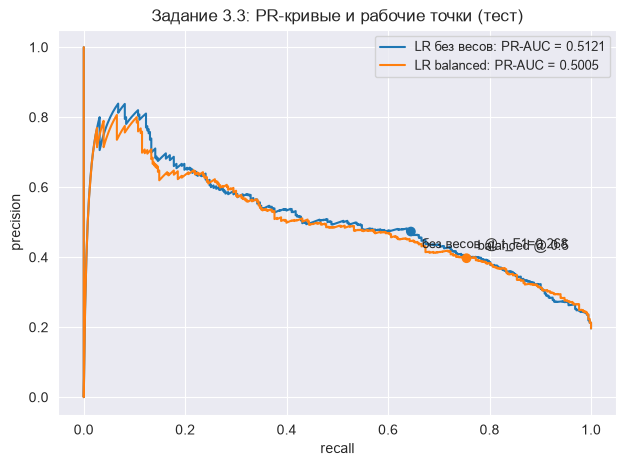

Рабочая точка balanced@0.5: precision = 0.397, recall = 0.755
Ближайшая точка кривой модели без весов: порог t* = 0.200 (precision 0.402, recall 0.757)


In [18]:
p_bal = pipe_bal.predict_proba(X_test)[:, 1]
p_nw = pipe_final.predict_proba(X_test)[:, 1]   # та же модель без весов, что и в 2.5

fig, ax = plt.subplots(figsize=(7.2, 5))
for p, name, color in [(p_nw, 'LR без весов', 'C0'), (p_bal, 'LR balanced', 'C1')]:
    pr, rc, _ = metrics.precision_recall_curve(y_test, p)
    ax.plot(rc, pr, color=color, label=f'{name}: PR-AUC = {metrics.average_precision_score(y_test, p):.4f}')

P_b = metrics.precision_score(y_test, (p_bal >= 0.5).astype(int), zero_division=0)
R_b = metrics.recall_score(y_test, (p_bal >= 0.5).astype(int), zero_division=0)
P_f1 = metrics.precision_score(y_test, (p_nw >= t_F1).astype(int), zero_division=0)
R_f1 = metrics.recall_score(y_test, (p_nw >= t_F1).astype(int), zero_division=0)
ax.scatter([R_f1, R_b], [P_f1, P_b], color=['C0', 'C1'], zorder=5)
ax.annotate(f'без весов @ t_F1={t_F1:.3f}', (R_f1, P_f1), textcoords='offset points', xytext=(8, -12), fontsize=9)
ax.annotate('balanced @ 0.5', (R_b, P_b), textcoords='offset points', xytext=(8, 6), fontsize=9)
ax.set(xlabel='recall', ylabel='precision', title='Задание 3.3: PR-кривые и рабочие точки (тест)')
ax.legend(fontsize=9)
plt.show()

# где кривая модели без весов проходит через рабочую точку balanced@0.5?
tgrid = np.linspace(0, 1, 2001)
pts = np.array([[metrics.precision_score(y_test, (p_nw >= t).astype(int), zero_division=0),
                 metrics.recall_score(y_test, (p_nw >= t).astype(int), zero_division=0)] for t in tgrid])
d = np.sqrt((pts[:, 0] - P_b) ** 2 + (pts[:, 1] - R_b) ** 2)
t_star = tgrid[d.argmin()]
print(f'Рабочая точка balanced@0.5: precision = {P_b:.3f}, recall = {R_b:.3f}')
print(f'Ближайшая точка кривой модели без весов: порог t* = {t_star:.3f} '
      f'(precision {pts[d.argmin(), 0]:.3f}, recall {pts[d.argmin(), 1]:.3f})')

- **Кривые близкие, но не совпадающие:** PR-AUC 0.5121 (без весов) против 0.5005 (balanced) — у взвешенной модели в зоне больших recall precision чуть ниже.

- **Сдвигает ли взвешивание порог? Да, практически целиком.** Рабочая точка balanced@0.5 (precision 0.397, recall 0.755) лежит почти точно на кривой модели без весов: ближайшая точка соответствует порогу ≈ 0.20 (precision 0.402, recall 0.757). То есть `class_weight='balanced'` в основном делает то же, что снижение порога с 0.5 примерно до 0.2 у обычной модели, лишь немного изменив сами вероятности (PR-AUC 0.5121 → 0.5005).

### Задание 3.4. Итоги (0.25 балла)

Сведите в одну таблицу все модели частей 2 и 3 (метрики на тестовой выборке). Какую модель и какой порог вы бы предложили сервису из сценария? Обоснуйте выбор, опираясь на метрики.

In [19]:
rows_34 = [quality_row(pipe, 0.5, 'LR без весов'),
           quality_row(pipe_final, t_F1, 'LR без весов, порог t_F1'),
           quality_row(pipe_final, t_R, 'LR без весов, порог t_R'),
           results_32["LR (balanced)"],
           results_32['RandomUnderSampler'],
           results_32['NearMiss (v2)'],
           results_32['RandomOverSampler'],
           results_32['SMOTE']]
cmp_34 = pd.DataFrame(rows_34)
print('Сводная таблица частей 2 и 3 (все метрики — на тестовой выборке):')
print(cmp_34.round(4).to_string(index=False))
print('\nПримечание: у модели без весов с разными порогами ROC-AUC и PR-AUC совпадают —')
print('это одна и та же модель, порог не влияет на AUC-метрики.')

Сводная таблица частей 2 и 3 (все метрики — на тестовой выборке):
                      Модель  Порог  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC
                LR без весов  0.500    0.8200     0.5976  0.2559 0.3583   0.8135  0.5121
    LR без весов, порог t_F1  0.268    0.7892     0.4732  0.6449 0.5459   0.8135  0.5121
     LR без весов, порог t_R  0.243    0.7651     0.4370  0.6789 0.5317   0.8135  0.5121
LR (class_weight='balanced')  0.500    0.7267     0.3970  0.7546 0.5203   0.8113  0.5005
          RandomUnderSampler  0.500    0.7297     0.4011  0.7624 0.5257   0.8094  0.5008
               NearMiss (v2)  0.500    0.5441     0.2819  0.8538 0.4238   0.7399  0.4001
           RandomOverSampler  0.500    0.7267     0.3973  0.7572 0.5211   0.8115  0.5002
                       SMOTE  0.500    0.7292     0.3992  0.7493 0.5209   0.8125  0.5040

Примечание: у модели без весов с разными порогами ROC-AUC и PR-AUC совпадают —
это одна и та же модель, порог не влияет на AUC-метри

- **Главный итог частей 2–3:** ни взвешивание классов, ни какой-либо из четырёх способов ресемплинга не улучшили качество *ранжирования* (ROC-AUC 0.74–0.81, PR-AUC 0.40–0.51; лучший ресэмплер — SMOTE, 0.5040, против 0.5121 у модели без всего). Вся разница между моделями — в том, где они «наивно» оказываются при пороге 0.5: у всех сбалансированных вариантов recall подскакивает до 0.75–0.85 ценой precision 0.28–0.40, а у модели без весов наоборот (precision 0.598 при recall 0.256).

- **Мой выбор для сервиса: логистическая регрессия без весов с порогом t_R = 0.243.** Аргументы: (1) бизнес-требование «в подборку попадает ≥ 70% хороших вин» на валидации дало recall 0.701 (на тесте 0.679 — близко к требованию), и при этом эта конфигурация даёт максимальный precision (0.437) среди всех строк таблицы с recall около 0.7; (2) ранжирование у всех моделей одинаково, так что усложнять пайплайн ресемплингом незачем — тот же эффект достигается простым выбором порога, а модель остаётся простым пайплайном StandardScaler + LogisticRegression, что важно для поддержки и воспроизводимости. Если бы сервис просил максимальный баланс (F1), выбрал бы тот же pipeline с порогом t_F1 = 0.268 (F1 = 0.546), но тогда требование recall ≥ 0.7 выполнялось бы лишь на 0.645.

### Сохранение модели (0 баллов, нужно для части 4)

Сохраните итоговую модель (весь пайплайн, а не только `LogisticRegression`), выбранный порог и тестовую выборку – они понадобятся в приложении. Допишите ячейку под свою итоговую модель.

Если работаете в Colab, скачайте папку `wine_app/` на свой компьютер (например, заархивируйте её и воспользуйтесь `google.colab.files.download`): приложение запускается локально.

In [20]:
import json
import joblib
from pathlib import Path

app_dir = Path('wine_app')
app_dir.mkdir(exist_ok=True)

final_model = pipe_final      # итоговый пайплайн: StandardScaler + LogisticRegression (без весов), обучен на всём X_train
final_threshold = t_R         # выбранный порог: макс. precision при recall >= 0.7 на валидации (задание 2.5)

joblib.dump(final_model, app_dir / 'model.joblib')
(app_dir / 'config.json').write_text(json.dumps({'threshold': float(final_threshold)}))
X_test.assign(target=y_test).to_csv(app_dir / 'test.csv', index=False)

print(f'Итоговая модель: LogisticRegression (без весов) внутри StandardScaler-пайплайна, порог = {final_threshold:.3f}')
print(f'Файлы сохранены в {app_dir.resolve()}:')
for f in sorted(app_dir.iterdir()):
    print(f'  - {f.name} ({f.stat().st_size / 1024:.1f} КБ)')

Итоговая модель: LogisticRegression (без весов) внутри StandardScaler-пайплайна, порог = 0.243
Файлы сохранены в /Users/ilyatikhonov/Documents/projects/ALL_ML/SE_ML/homework/hw_3/wine_app:
  - README.md (4.2 КБ)
  - app.py (11.5 КБ)
  - config.json (0.0 КБ)
  - model.joblib (2.1 КБ)
  - requirements.txt (0.1 КБ)
  - test.csv (115.1 КБ)


## <font color="green">Часть 4. Демо-приложение на Streamlit (2.5 балла)</font>

Модель в ноутбуке видите только вы. Чтобы ей мог пользоваться сомелье сервиса (и чтобы он понимал, почему меняется подборка при изменении порога), сделаем небольшое веб-приложение.

[Streamlit](https://docs.streamlit.io/) это библиотека, которая которая превращает обычный Python-скрипт в веб-страницу: каждый вызов вроде `st.slider(...)` или `st.write(...)` рисует элемент интерфейса, а при любом действии пользователя скрипт перезапускается сверху вниз. Минимальный пример:

```python
import streamlit as st

t = st.slider('Порог', 0.0, 1.0, 0.5)
st.write('Вы выбрали порог', t)
```

Приложение запускается **локально**, а не в Colab:

```bash
pip install streamlit
streamlit run app.py
```

Полезные элементы: [`st.number_input`](https://docs.streamlit.io/develop/api-reference/widgets/st.number_input), [`st.slider`](https://docs.streamlit.io/develop/api-reference/widgets/st.slider), [`st.tabs`](https://docs.streamlit.io/develop/api-reference/layout/st.tabs), [`st.file_uploader`](https://docs.streamlit.io/develop/api-reference/widgets/st.file_uploader), [`st.download_button`](https://docs.streamlit.io/develop/api-reference/widgets/st.download_button), [`st.pyplot`](https://docs.streamlit.io/develop/api-reference/charts/st.pyplot), [`st.metric`](https://docs.streamlit.io/develop/api-reference/data/st.metric), [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource) (чтобы не загружать модель заново при каждом перезапуске скрипта).

Приложение `wine_app/app.py` использует файлы, сохранённые в ячейке выше (`model.joblib`, `config.json`, `test.csv`). **Модель внутри приложения не обучается.**

### Задание 4.1. Оценка одного вина (0.5 балла)

Сделайте вкладку, на которой пользователь вводит 12 признаков вина (диапазоны и значения по умолчанию возьмите из данных, например минимум, максимум и медиану по `test.csv`; признак `is_red` – переключатель «красное / белое»). Сделайте сайдбар с интерактивным ползунком значения порога, установите порог по умолчанию значением из файла `config.json`. Приложение показывает вероятность того, что вино хорошее, и решение модели при установленном пороге.

### Задание 4.2. Интерактивная визуализация модельных метрик (0.5 балла)

Сделайте вкладку «Модельные метрики». При изменении порога на тестовой выборке пересчитываются и выводятся:
- матрица ошибок;
- precision, recall и $F_1$;
- ROC- и PR-кривые, на которых отмечена точка, соответствующая текущему порогу.

Добавьте короткий текст для сомелье: что произойдёт с подборкой, если порог увеличить или уменьшить.

### Задание 4.3. Пакетное предсказание (0.5 балла)

Сделайте вкладку, на которой пользователь загружает CSV-файл с признаками вин (без столбца `target`), а приложение показывает таблицу с вероятностью и решением для каждого вина и даёт скачать её через `st.download_button`. Порог для этой вкладки берётся из слайдера задания 4.2 (подсказка: [`st.session_state`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.session_state)) или задаётся отдельно – на ваш выбор.

Приложение не должно падать, если в файле не хватает столбцов: в этом случае выведите понятное сообщение об ошибке (`st.error`).

### Задание 4.4. Что выучила модель (0.25 балла)

Сделайте вкладку с горизонтальной столбчатой диаграммой коэффициентов логистической регрессии (после масштабирования признаков), отсортированных по значению. Подпишите, какие признаки сильнее всего «голосуют» за хорошее вино, а какие – против.

### Задание 4.5. Кэширование (0.25 балла)

Streamlit выполняет `app.py` заново при каждом действии пользователя: сдвинули слайдер порога – скрипт отработал сверху вниз ещё раз. Без кэширования при каждом движении слайдера модель снова читается с диска, а вероятности на тестовой выборке пересчитываются, хотя от порога они не зависят.

1. Модель загружается функцией с декоратором [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource): один объект на весь сервер. Путь к файлу строится от папки, где лежит `app.py` (`Path(__file__).parent`), а не от текущей директории.
2. `test.csv` читается функцией с декоратором [`st.cache_data`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_data).
3. Вероятности класса 1 на тестовой выборке считаются один раз, в функции с `st.cache_data`. При движении слайдера в задании 4.2 меняется только сравнение с порогом, `predict_proba` заново не вызывается. Подсказка: аргумент, который Streamlit не должен хешировать (например, модель), называют с подчёркиванием в начале: `def test_proba(_model, X): ...`.

Ответьте в `README.md` или в комментарии в `app.py`: почему для модели используется `st.cache_resource`, а для таблиц – `st.cache_data`? Что изменится, если вызвать `joblib.load` без декоратора?

Использование `joblib.load` без декоратора или загрузка модели через `st.cache_data` за этот пункт не засчитываются.

### Задание 4.6. Оформление и сдача (0.5 балла)

1. Сдайте папку `wine_app/` (архивом или укажите в клетке ниже ссылку на Github репозиторий) со следующим содержимым:
- `app.py`;
- `model.joblib`, `config.json`, `test.csv`;
- `requirements.txt` с версиями библиотек, при которых приложение запускается;
- `README.md`: инструкция о том, как запустить приложение с указанием версии Python интерпретатора.

2. Проведите деплой приложения на [Streamlit Community Cloud](https://streamlit.io/cloud).

**Сдача задания 4.6.1 — ссылка на репозиторий:**

Код, артефакты и история решения: https://github.com/ilyaytrewq/ml_hse_se_2026
Папка приложения: [`homework/hw_3/wine_app/`](https://github.com/ilyaytrewq/ml_hse_se_2026/tree/dev/homework/hw_3/wine_app) (ветка `dev`) — `app.py`, `model.joblib`, `config.json`, `test.csv`, `requirements.txt`, `README.md`.

**Опишите общие мысли о работе. Это место для вашей рефлексии – необязательное, но полезное.** 🍷

**Общие мысли о работе.**

1. Своя реализация — лучший способ понять «штатную»: наш GD в 1.4 повторил качество sklearn (ROC-AUC 0.8388 против 0.8387), но только после досходимости (макс. |Δw| 0.18 → 0.0007) — и именно недосходимость, а не регуляризация, была причиной расхождения весов.
2. Пороговые метрики и AUC-метрики отвечают на разные вопросы: все способы балансировки (веса, 4 ресэмплера) лишь сдвинули рабочую точку (recall 0.26 → 0.75–0.85), не улучшив ранжирование (лучший из них — SMOTE: PR-AUC 0.5040 против 0.5121 у модели без всего), поэтому для сценария хватило выбора порога (t_R = 0.243) у самой простой модели.
3. Валидация — не гарантия: порог, давший на валидации recall 0.701, на тесте дал 0.679; при подборе порога под бизнес-требование полезно закладывать запас.
4. Из технических мелочей: численно стабильная сигмоида и `np.clip` в log-loss; ресемплинг — только через imblearn-пайплайн и только на train; порядок шагов «масштабирование → ресемплинг» важен для метрических ресэмплеров (NearMiss: F1 0.424 → 0.476 при смене порядка).
5. Приложение в `wine_app/` (app.py, model.joblib, config.json, test.csv, requirements.txt, README.md) — модель доходит до пользователя. Деплой на Streamlit Community Cloud сделаю следующим шагом после пуша репозитория в GitHub.